# Evaluation

In the order I looked at things:

1. is the demo data ok, does the policy train
2. without pushes: how often should the policy replan (which baseline is fair)
3. how much do pushes hurt
4. does the world model notice them
5. does replanning on surprise help, and is it more than "replanning more often"
6. why the effect is not bigger
7. the history bug
8. one episode

Sections 1-3 and 5-7 only read `eval/results/` (from `eval/benchmark.py`, `eval/detection.py`).
4 and 8 run a few new episodes (~1 min). Figures go to `eval/figs/`.

In [1]:
import os, sys, json
if os.path.basename(os.getcwd()) == "eval":
    os.chdir("..")
sys.path.insert(0, ".")

import numpy as np
import matplotlib.pyplot as plt
import torch
torch.set_num_threads(2)

from rollout import kick_schedule

res = json.load(open("eval/results/benchmark.json"))
det = json.load(open("eval/results/detection.json"))
N = res["n"]
CONDS = ["clean", "small", "medium", "large"]
SEEDS = np.arange(10000, 10000 + N)
FIG = "eval/figs"
os.makedirs(FIG, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
rng = np.random.default_rng(0)

def episodes(cond, name):
    d = np.load(f"eval/results/episodes/{cond}/{name}.npz")
    return {k: d[k] for k in d.files}

def success(cond, name):
    return res["conditions"][cond][name]["success"]

def ci(p):
    return 1.96 * np.sqrt(p * (1 - p) / N)

## 1. Demos and policy training

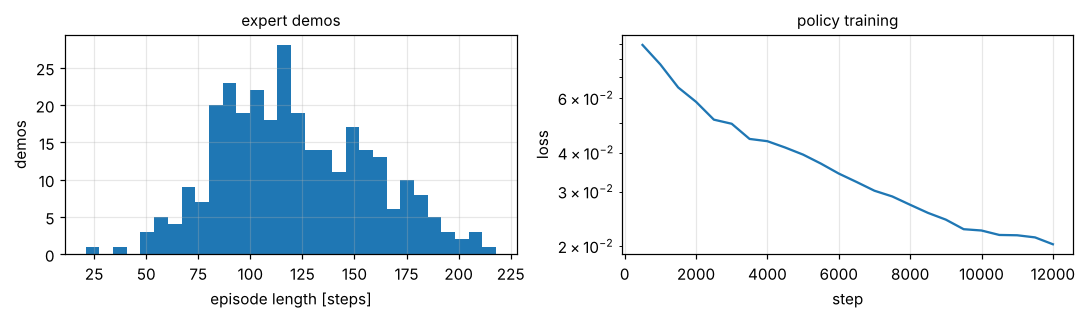

In [2]:
d = np.load("data/demos.npz")
lens = np.diff(np.r_[0, d["ep_end"]])
log = np.genfromtxt("runs/policy/log.csv", delimiter=",", names=True)

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].hist(lens, bins=30)
ax[0].set_xlabel("episode length [steps]"); ax[0].set_ylabel("demos"); ax[0].set_title("expert demos", fontsize=10)
ax[1].plot(log["step"], log["loss"])
ax[1].set_xlabel("step"); ax[1].set_ylabel("loss"); ax[1].set_yscale("log")
ax[1].set_title("policy training", fontsize=10)
plt.tight_layout(); plt.savefig(f"{FIG}/01_demos_and_training.png")

## 2. No pushes: how often to replan

The policy predicts 16 actions, executes k of them, then plans again.

{1: np.float64(0.86), 2: np.float64(0.917), 4: np.float64(0.923), 8: np.float64(0.917), 16: np.float64(0.747)}


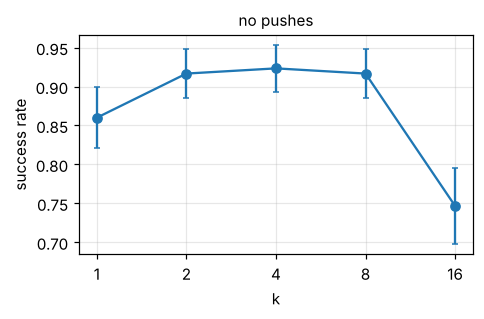

In [3]:
ks = [1, 2, 4, 8, 16]
y = np.array([success("clean", f"k={k}") for k in ks])
fig, ax = plt.subplots(figsize=(4.5, 3))
ax.errorbar(ks, y, yerr=ci(y), fmt="o-", capsize=2)
ax.set_xscale("log", base=2); ax.set_xticks(ks); ax.set_xticklabels(ks)
ax.set_xlabel("k"); ax.set_ylabel("success rate")
ax.set_title("no pushes", fontsize=10)
plt.tight_layout(); plt.savefig(f"{FIG}/02_horizon_no_pushes.png")
print({k: round(v, 3) for k, v in zip(ks, y)})

k=1 is worse (plans switch between modes and the agent dithers), k=16 is worse (the end of each plan is too far ahead). k=8, the Diffusion Policy default, is the fair baseline. k=16 stays in as the "long chunks" case.

## 3. How much do pushes hurt

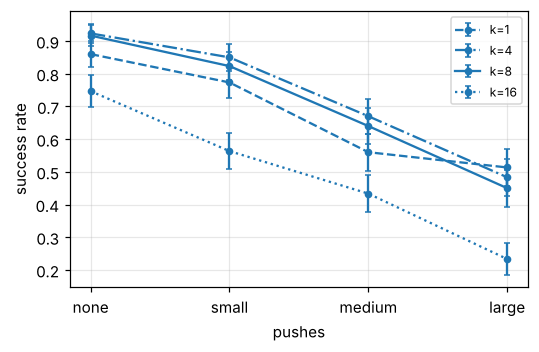

In [4]:
fig, ax = plt.subplots(figsize=(5, 3.3))
for k, ls in [(1, "--"), (4, "-."), (8, "-"), (16, ":")]:
    y = np.array([success(c, f"k={k}") for c in CONDS])
    ax.errorbar(range(4), y, yerr=ci(y), color="C0", ls=ls, marker="o", ms=4, capsize=2, label=f"k={k}")
ax.set_xticks(range(4)); ax.set_xticklabels(["none", "small", "medium", "large"])
ax.set_xlabel("pushes"); ax.set_ylabel("success rate"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{FIG}/03_pushes_hurt.png")

Small pushes cost ~10 points, large ones about half of the successes. Replanning every step instead of every 8 does not help much.

## 4. Does the world model notice the pushes

New rollouts: 50 episodes, k=8, medium pushes, nothing is triggered, only measured.

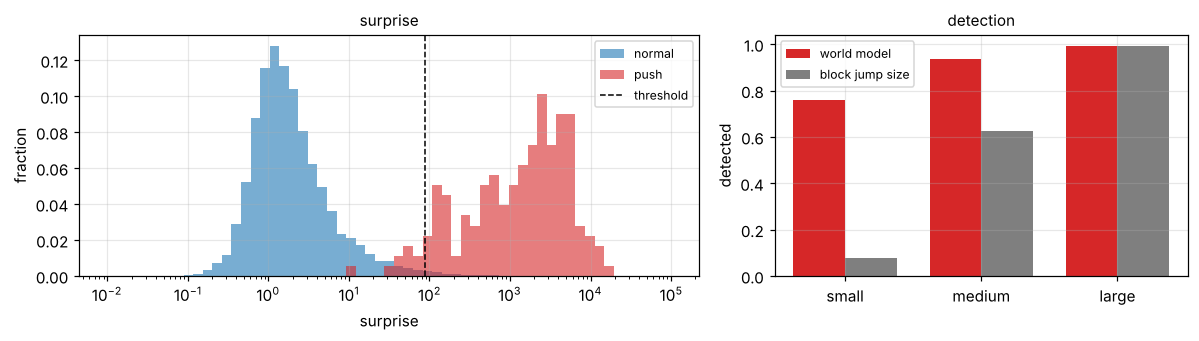

In [5]:
from policy import Policy
from rollout import Strategy, run
from worldmodel import WorldModel

policy = Policy("runs/policy/ema.pt")
wm = WorldModel(); wm.load_state_dict(torch.load("runs/wm/model.pt"))
eps = run(policy, Strategy(8), np.arange(10000, 10050), wm=wm, kicks="medium", keep_log=True)
sur = np.concatenate([e.log["surprise"] for e in eps])
pushed = np.concatenate([[k is not None for k in e.log["kick"]] for e in eps])

bins = np.logspace(-2, 5, 60)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2), gridspec_kw={"width_ratios": [1.5, 1]})
# each histogram sums to 1, otherwise the push steps are invisible next to 11k normal steps
ax[0].hist(sur[~pushed], bins, weights=np.full((~pushed).sum(), 1 / (~pushed).sum()), alpha=.6, label="normal")
ax[0].hist(sur[pushed], bins, weights=np.full(pushed.sum(), 1 / pushed.sum()), alpha=.6, color="C3", label="push")
ax[0].axvline(res["thr"]["surprise"], color="k", ls="--", lw=1, label="threshold")
ax[0].set_xscale("log"); ax[0].set_xlabel("surprise"); ax[0].set_ylabel("fraction"); ax[0].set_title("surprise", fontsize=10); ax[0].legend(fontsize=8)

x = np.arange(3)
for i, (k, lab) in enumerate([("surprise", "world model"), ("jump", "block jump size")]):
    ax[1].bar(x + (i - .5) * .38, [det[c][k]["detected"] for c in det], .38, label=lab, color=["C3", "C7"][i])
ax[1].set_xticks(x); ax[1].set_xticklabels(list(det)); ax[1].set_ylabel("detected")
ax[1].set_title("detection", fontsize=10); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{FIG}/04_detection.png")

The world model catches most pushes that are smaller than normal block motion, the jump detector only the big ones.

## 5. Does replanning on surprise help

Same base policy, plus: replan when surprised / when the block jumped / at random times with the same rate.

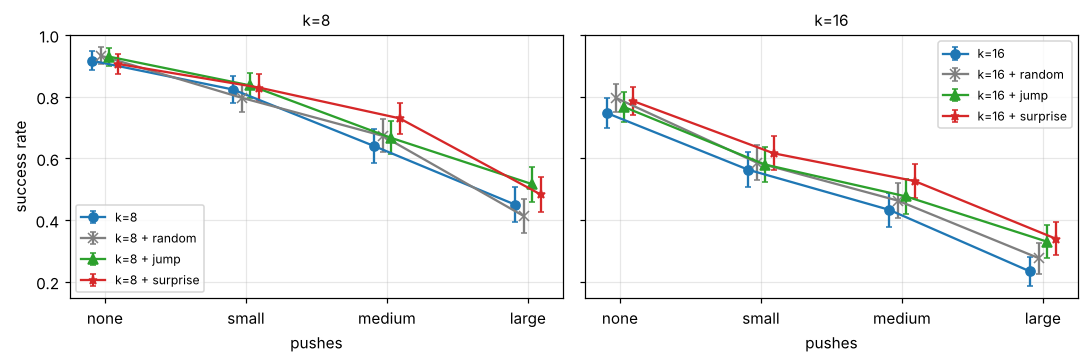

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, k in zip(axs, [8, 16]):
    for name, col, m in [(f"k={k}", "C0", "o"), (f"k={k} + random", "C7", "x"), (f"k={k} + jump", "C2", "^"), (f"k={k} + surprise", "C3", "*")]:
        y = np.array([success(c, name) for c in CONDS])
        ax.errorbar(np.arange(4) + {"o": -.09, "x": -.03, "^": .03, "*": .09}[m], y, yerr=ci(y), color=col, marker=m, ms=6, capsize=2, label=name)
    ax.set_xticks(range(4)); ax.set_xticklabels(["none", "small", "medium", "large"]); ax.set_xlabel("pushes")
    ax.set_title(f"k={k}", fontsize=10); ax.legend(fontsize=8)
axs[0].set_ylabel("success rate")
plt.tight_layout(); plt.savefig(f"{FIG}/05_triggers.png")

In [7]:
def paired(a, b, cond):
    a = (episodes(cond, a)["success_step"] > 0).astype(float)
    b = (episodes(cond, b)["success_step"] > 0).astype(float)
    i = rng.integers(0, N, (2000, N))
    dd = a[i].mean(1) - b[i].mean(1)
    return f"{100 * (a.mean() - b.mean()):+.0f} [{100 * np.quantile(dd, .025):+.0f}, {100 * np.quantile(dd, .975):+.0f}]"

lines = [f"paired differences in success rate, percentage points, 95% bootstrap CI over the {N} seeds", "",
         "| | " + " | ".join(CONDS) + " |", "|---|" + "---|" * 4]
for a, b in [("k=8 + surprise", "k=8"), ("k=8 + surprise", "k=8 + random"), ("k=8 + surprise", "k=8 + jump"),
             ("k=16 + surprise", "k=16"), ("k=16 + surprise", "k=16 + random"), ("k=16 + surprise", "k=16 + jump")]:
    lines.append(f"| {a} vs {b} | " + " | ".join(paired(a, b, c) for c in CONDS) + " |")
open("eval/results/tables.md", "w").write("\n".join(lines) + "\n")
print("\n".join(lines))

paired differences in success rate, percentage points, 95% bootstrap CI over the 300 seeds

| | clean | small | medium | large |
|---|---|---|---|---|
| k=8 + surprise vs k=8 | -1 [-6, +4] | +1 [-5, +7] | +9 [+2, +16] | +3 [-4, +11] |
| k=8 + surprise vs k=8 + random | -3 [-7, +2] | +3 [-3, +9] | +6 [-1, +13] | +7 [-1, +15] |
| k=8 + surprise vs k=8 + jump | -2 [-6, +1] | -1 [-6, +5] | +6 [-1, +14] | -3 [-11, +4] |
| k=16 + surprise vs k=16 | +4 [-2, +10] | +5 [-2, +13] | +9 [+1, +17] | +11 [+3, +18] |
| k=16 + surprise vs k=16 + random | -1 [-7, +6] | +3 [-5, +10] | +6 [-2, +14] | +6 [-1, +14] |
| k=16 + surprise vs k=16 + jump | +2 [-4, +8] | +4 [-4, +11] | +5 [-3, +13] | +1 [-6, +8] |


Clear gain over the same schedule for medium pushes (both k) and large pushes with k=16. Against random replanning and the jump trigger the difference is 5-7 points, but the intervals include 0.

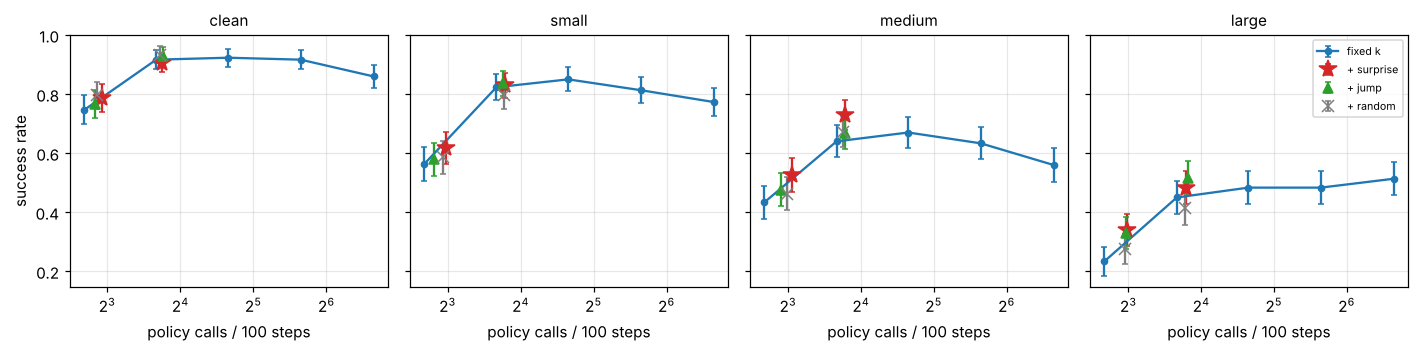

In [8]:
fig, axs = plt.subplots(1, 4, figsize=(13, 3.3), sharey=True)
MARK = {"surprise": ("*", "C3", 12), "jump": ("^", "C2", 7), "random": ("x", "C7", 8)}
for ax, c in zip(axs, CONDS):
    s = res["conditions"][c]
    x = [s[f"k={k}"]["calls_per_100"] for k in ks]
    y = np.array([s[f"k={k}"]["success"] for k in ks])
    ax.errorbar(x, y, yerr=ci(y), fmt="o-", color="C0", ms=4, capsize=2, label="fixed k")
    for k in (8, 16):
        for t, (m, col, ms) in MARK.items():
            v = s[f"k={k} + {t}"]
            ax.errorbar(v["calls_per_100"], v["success"], yerr=ci(v["success"]), fmt=m, color=col, ms=ms, capsize=2,
                        label=f"+ {t}" if k == 8 else None)
    ax.set_xscale("log", base=2); ax.set_title(c, fontsize=10); ax.set_xlabel("policy calls / 100 steps")
axs[0].set_ylabel("success rate"); axs[-1].legend(fontsize=7)
plt.tight_layout(); plt.savefig(f"{FIG}/06_success_vs_compute.png")

Same numbers against compute (blue points left to right: k=16, 8, 4, 2, 1). With pushes, k=8 + surprise is about as good as replanning every 1-4 steps, at 1/7 to 1/2 of the policy calls.

## 6. Why the effect is not bigger

Coverage around every push, relative to just before it.

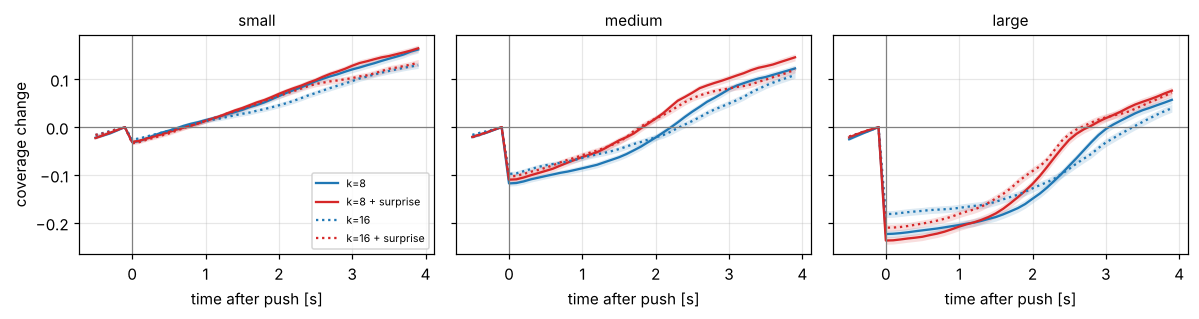

In [9]:
def peri(cond, name, pre=5, post=40):
    cov = episodes(cond, name)["cov"]
    out = []
    for i, sd in enumerate(SEEDS):
        c = cov[i].copy()
        last = np.where(~np.isnan(c))[0][-1]
        c[last + 1:] = c[last]           # after success it stays solved
        for t0 in kick_schedule(sd, cond):
            if t0 - pre < 0 or t0 + post >= 300 or t0 > last:
                continue
            out.append(c[t0 - pre:t0 + post] - c[t0 - 1])
    return np.array(out)

fig, axs = plt.subplots(1, 3, figsize=(11, 3), sharey=True)
t = np.arange(-5, 40) / 10
for ax, c in zip(axs, CONDS[1:]):
    for name, col, ls in [("k=8", "C0", "-"), ("k=8 + surprise", "C3", "-"), ("k=16", "C0", ":"), ("k=16 + surprise", "C3", ":")]:
        x = peri(c, name)
        m, se = x.mean(0), x.std(0) / np.sqrt(len(x))
        ax.plot(t, m, color=col, ls=ls, label=name)
        ax.fill_between(t, m - se, m + se, color=col, alpha=.15, lw=0)
    ax.axvline(0, color="gray", lw=.8); ax.axhline(0, color="gray", lw=.8)
    ax.set_title(c, fontsize=10); ax.set_xlabel("time after push [s]")
axs[0].set_ylabel("coverage change"); axs[0].legend(fontsize=7)
plt.tight_layout(); plt.savefig(f"{FIG}/07_after_push.png")

Replanning right away gets the recovery going ~0.3-0.5 s earlier, but getting back takes 2-3 s anyway. Reaction time is not the main bottleneck here.

## 7. The history bug

Right after a triggered replan, the 2-step observation history contains the block before and after the push (a 30 px jump in 0.1 s, never in the demos). Fix: overwrite the old block pose. Only rerun for some cells.

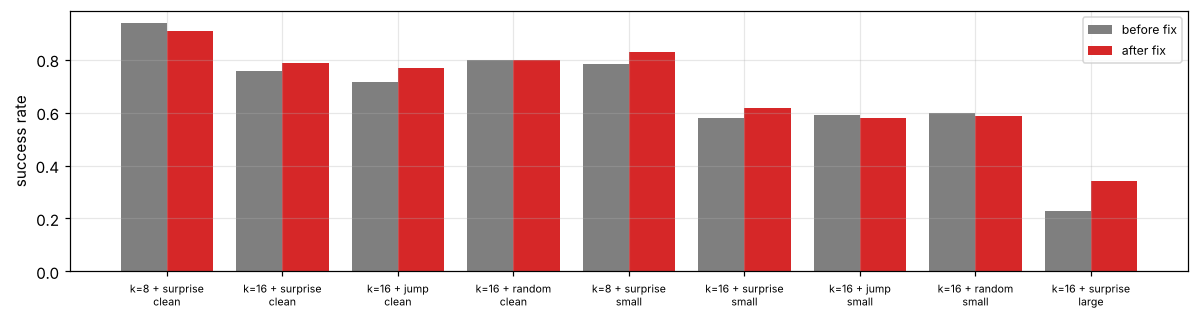

In [10]:
cells_ = [(c, n) for c in CONDS for n in ["k=8 + surprise", "k=16 + surprise", "k=16 + jump", "k=16 + random"]
          if n + " (no hist fix)" in res["conditions"][c]]
labels = [f"{n}\n{c}" for c, n in cells_]
before = [success(c, n + " (no hist fix)") for c, n in cells_]
after = [success(c, n) for c, n in cells_]
fig, ax = plt.subplots(figsize=(11, 3))
x = np.arange(len(cells_))
ax.bar(x - .2, before, .4, color="C7", label="before fix")
ax.bar(x + .2, after, .4, color="C3", label="after fix")
ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=7); ax.set_ylabel("success rate"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{FIG}/08_history_fix.png")

Biggest effect where it matters most (large pushes, k=16: 23 -> 34%). Random replanning barely changes, it rarely lands right after a push.

## 8. One episode

Medium pushes, picked from seeds 10000-10019 as one where the two end differently. Red lines = pushes, dots = triggered replans.

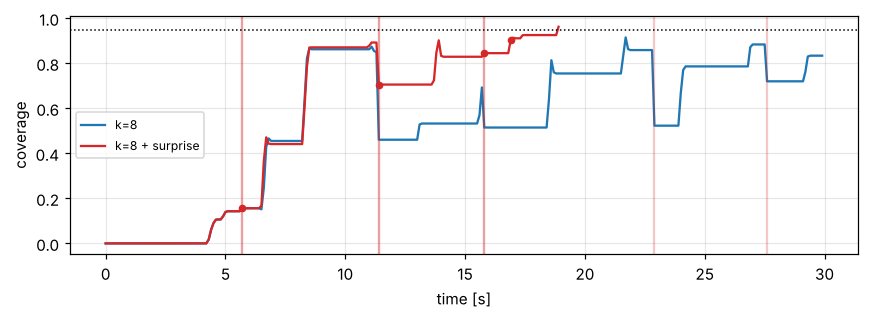

In [11]:
thr = res["thr"]["surprise"]
fig, ax = plt.subplots(figsize=(8, 3))
for st, col in [(Strategy(8), "C0"), (Strategy(8, "surprise", thr), "C3")]:
    policy.gen = torch.Generator().manual_seed(1)
    e = run(policy, st, [10006], wm=wm, kicks="medium", keep_log=True)[0]
    tt = np.arange(len(e.log["cov"])) / 10
    ax.plot(tt, e.log["cov"], color=col, label=st.name)
    r = np.array(e.log["replan"], bool)
    ax.plot(tt[r], np.array(e.log["cov"])[r], "o", color=col, ms=4)
    for i, k in enumerate(e.log["kick"]):
        if k is not None:
            ax.axvline(i / 10, color="C3", alpha=.25)
ax.axhline(.95, color="k", ls=":", lw=1)
ax.set_xlabel("time [s]"); ax.set_ylabel("coverage"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{FIG}/09_episode.png")